In [2]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
import h5py

from pyoculus.fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot

In [3]:
results_dir = Path("num_results_loc/computed_manifolds")

configs = list(range(11, 20)) + list(range(110, 129)) + [21, 22, 23]

parameters = {}

for config_id in configs:

    # Load parameters
    path_json = results_dir / f"parameters_{config_id}.json"
    with open(path_json, "r", encoding="utf-8") as f:
        parameters[config_id] = json.load(f)


In [11]:
temperature_dir = Path("num_results_loc/FaADE")

def plot_temperature(config_id, ax=None, t_f=0.01, k_value=10.0, nx=201, cmap="viridis", alpha=1.0, vmin=None, vmax=None):
    """
    Plot the 2D temperature field on the (x, y) plane.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axis on which to plot the temperature field.
    params : dict
        Configuration parameters.
    t_f : float
        Final simulation time.
    k_value : float
        Exponent defining kappa_perp/kappa_parallel = 10^(-k).
    nx : int
        Spatial resolution.
    cmap : str
        Temperature colormap.
    alpha : float
        Opacity of the temperature field.
    vmin, vmax : float, optional
        Lower and upper limits of the color scale.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    else:
        fig = ax.figure

    params=parameters[config_id]

    delta1 = params["delta1"]
    delta2 = params["delta2"]
    iota = params["iota_prime"]

    filename = (
        f"2I_k{k_value}_tf{t_f}_"
        f"d{delta1}_{delta2}_res{nx}_"
        f"m1_dT_iota{float(iota)}_Neumann.jld2"
    )

    path = temperature_dir / filename

    if not path.exists():
        print(f"Temperature file not found: {filename}")
        return None

    with h5py.File(path, "r") as f:
        soln = f["soln"]

        # Dereference u to obtain the array of solutions
        u = f[soln["u"]]

        # Access the second solution and dereference it
        T = np.asarray(f[u[1]]).squeeze()

    # Assuming T.shape = (ny, nx)
    ny, nx_T = T.shape

    x = np.linspace(0, 2, nx_T)
    y = np.linspace(0, 2*np.pi, ny)

    # Plot the temperature field
    pcm = ax.pcolormesh(x, y, T, cmap=cmap, shading="auto", alpha=alpha, vmin=vmin, vmax=vmax, zorder=0)

    # Colorbar
    cbar = ax.figure.colorbar(pcm, ax=ax)
    cbar.set_label(r"$T(x,y)$")

    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$y$")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2*np.pi)

    return fig, ax

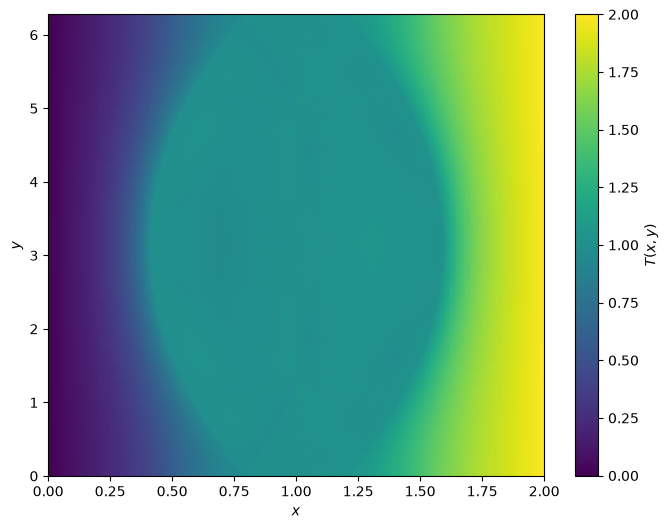

In [12]:
config_id = 13

fig, ax = plot_temperature(config_id=config_id, t_f=0.01, k_value=10.0, nx=201)